# Lab Assignment: English-to-German Machine Translation with a Transformer

**Objective:**
The goal of this assignment is to fine-tune a pre-trained **Transformer** model for machine translation. You will load a dataset, fine-tune the model, and evaluate it using the BLEU score.

You will also compare your new model's performance and architecture against a previous **LSTM-based** model, and visualize the **self-attention** and **cross-attention** mechanisms that make the Transformer so powerful.


## Part 1: Setup and Environment

First, install all the necessary libraries.

In [ ]:
!pip -q install -U transformers datasets evaluate sacrebleu sentencepiece accelerate tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 76.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 39.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 4.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 25.0.1 which is incompatible.


## Part 2: Data Loading and Pre-processing

### 1. Load the Dataset
We have to use previously provided dataset, which contains parallel sentences for English-to-German translation.

In [ ]:
import os
import zipfile
import pandas as pd
from pathlib import Path
from datasets import Dataset, DatasetDict

# Download the same English-German dataset used in the previous LSTM lab
if not Path("deu.txt").exists():
    !wget -q https://www.manythings.org/anki/deu-eng.zip
    with zipfile.ZipFile("deu-eng.zip", "r") as zip_ref:
        zip_ref.extractall(".")

# Load the first 10,000 English-German sentence pairs
data = pd.read_csv(
    "deu.txt",
    sep="\t",
    header=None,
    names=["english", "german", "extra"],
    usecols=[0, 1]
)

data = data.iloc[:10000].copy()

print("Number of sentence pairs:", len(data))
print(data.head())

# Convert to Hugging Face Dataset
dataset = Dataset.from_pandas(data, preserve_index=False)

# Split into 80% train, 10% validation, 10% test
train_test = dataset.train_test_split(test_size=0.20, seed=42)

validation_test = train_test["test"].train_test_split(
    test_size=0.50,
    seed=42
)

dataset = DatasetDict({
    "train": train_test["train"],
    "validation": validation_test["train"],
    "test": validation_test["test"]
})

print("\nDataset:")
print(dataset)

Number of sentence pairs: 10000
  english      german
0     Go.        Geh.
1     Hi.      Hallo!
2     Hi.  Grüß Gott!
3    Run!       Lauf!
4    Run.       Lauf!

Dataset:
DatasetDict({
    train: Dataset({
        features: ['english', 'german'],
        num_rows: 8000
    })
    validation: Dataset({
        features: ['english', 'german'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['english', 'german'],
        num_rows: 1000
    })
})


### 2. Load Tokenizer and Model
We will use a pre-trained model from the Helsinki-NLP group, `opus-mt-en-de`, which is a lightweight and efficient Transformer specifically designed for English-to-German translation.

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_checkpoint = "Helsinki-NLP/opus-mt-en-de"

tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
model = AutoModelForSeq2SeqLM.from_pretrained(model_checkpoint)

print("Tokenizer and Transformer model loaded successfully.")
print("Model:", model_checkpoint)

config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/768k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/797k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.27M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  298MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Tokenizer and Transformer model loaded successfully.
Model: Helsinki-NLP/opus-mt-en-de


### 3. Pre-processing Function
We must tokenize both the English (input) and German (target) sentences. For seq2seq models, the tokenized target sentences are assigned to the `labels` key.

In [ ]:
def preprocess_function(examples):
    model_inputs = tokenizer(
        examples["english"],
        max_length=128,
        truncation=True
    )

    labels = tokenizer(
        text_target=examples["german"],
        max_length=128,
        truncation=True
    )

    model_inputs["labels"] = labels["input_ids"]

    return model_inputs

### 4. Apply Pre-processing
Use the `.map()` function to apply this tokenization to the entire dataset.

In [ ]:
tokenized_dataset = dataset.map(
    preprocess_function,
    batched=True,
    remove_columns=dataset["train"].column_names
)

print(tokenized_dataset)

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 8000
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1000
    })
})


## Part 3: Fine-Tuning the Model

### 1. Define Evaluation Metric (BLEU)
Machine translation is evaluated using the **BLEU score**. You can load the `sacrebleu` metric and create a `compute_metrics` function to use during training.

In [ ]:
import evaluate
import numpy as np

metric = evaluate.load("sacrebleu")

def compute_metrics(eval_preds):
    predictions, labels = eval_preds

    if isinstance(predictions, tuple):
        predictions = predictions[0]

    decoded_predictions = tokenizer.batch_decode(
        predictions,
        skip_special_tokens=True
    )

    labels = np.where(
        labels != -100,
        labels,
        tokenizer.pad_token_id
    )

    decoded_labels = tokenizer.batch_decode(
        labels,
        skip_special_tokens=True
    )

    decoded_predictions = [
        prediction.strip()
        for prediction in decoded_predictions
    ]

    decoded_labels = [
        [label.strip()]
        for label in decoded_labels
    ]

    result = metric.compute(
        predictions=decoded_predictions,
        references=decoded_labels
    )

    return {
        "bleu": round(result["score"], 2)
    }

### 2. Configure Training
We will use the `Seq2SeqTrainer` and `Seq2SeqTrainingArguments` classes to manage the fine-tuning process.

In [ ]:
import torch
from transformers import (
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model
)

training_args = Seq2SeqTrainingArguments(
    output_dir="./transformer_en_de",
    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    weight_decay=0.01,

    num_train_epochs=3,

    predict_with_generate=True,

    generation_max_length=128,
    generation_num_beams=4,

    save_total_limit=2,

    logging_steps=100,
    report_to="none",

    fp16=torch.cuda.is_available(),

    seed=42
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,

    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],

    processing_class=tokenizer,

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

print("Training configuration created successfully.")

Training configuration created successfully.


### 3. Start Training


In [ ]:
train_result = trainer.train()

print("\nTraining completed.")

print("\nTraining statistics:")
print(train_result.metrics)

# Save the final fine-tuned Transformer
trainer.save_model("./final_transformer_en_de")
tokenizer.save_pretrained("./final_transformer_en_de")

print("\nFinal Transformer model saved to:")
print("./final_transformer_en_de")

Epoch,Training Loss,Validation Loss,Bleu
1,0.620428,0.592376,54.130000
2,0.498935,0.574486,53.920000
3,0.446186,0.574214,53.960000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training completed.

Training statistics:
{'train_runtime': 163.2627, 'train_samples_per_second': 147.002, 'train_steps_per_second': 9.188, 'total_flos': 45957708251136.0, 'train_loss': 0.5296463928222657, 'epoch': 3.0}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Final Transformer model saved to:
./final_transformer_en_de


### 4. Evaluate the Model
After training, run the final evaluation on the test set.

In [ ]:
evaluation_results = trainer.evaluate(
    eval_dataset=tokenized_dataset["test"],
    metric_key_prefix="test"
)

print("Final Test Results:")
print(evaluation_results)

if "test_bleu" in evaluation_results:
    print(
        f"\nFinal Test BLEU Score: "
        f"{evaluation_results['test_bleu']:.2f}"
    )

Training Loss,Validation Loss,Epoch,Bleu
0.446186,0.549458,3,51.810000


Final Test Results:
{'test_loss': 0.5494575500488281, 'test_bleu': 51.81}

Final Test BLEU Score: 51.81


## Part 4: Inference (Testing the Translator)

Now use your fine-tuned model to translate new sentences using the `pipeline` utility.

In [ ]:
# Test with new sentences using the fine-tuned Transformer model

import torch

# Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
model.eval()


def translator(text, max_length=128, num_beams=4):
    """
    Translate one English sentence into German
    using the fine-tuned Helsinki-NLP Transformer.
    """

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        generated_ids = model.generate(
            **inputs,
            max_length=max_length,
            num_beams=num_beams
        )

    translated_text = tokenizer.decode(
        generated_ids[0],
        skip_special_tokens=True
    )

    return [
        {
            "translation_text": translated_text
        }
    ]


# Required test sentences
text1 = "Hello, how are you doing today?"
text2 = "The transformer model is a powerful architecture for NLP."
text3 = "This assignment is for my machine learning lab."


# Translate and display the results
texts = [text1, text2, text3]

for text in texts:

    result = translator(
        text,
        max_length=128,
        num_beams=4
    )

    print("English:", text)
    print("German :", result[0]["translation_text"])
    print("-" * 70)

English: Hello, how are you doing today?
German : Hallo, wie geht es dir heute?
----------------------------------------------------------------------
English: The transformer model is a powerful architecture for NLP.
German : Das Transformatorenmodell ist eine leistungsstarke Architektur für NLP.
----------------------------------------------------------------------
English: This assignment is for my machine learning lab.
German : Dieser Auftrag ist für mein maschinelles Lernlabor.
----------------------------------------------------------------------


## Part 5: Comparative Analysis (Transformer vs. LSTM)

In this section, you will directly compare the output of your new Transformer model with the LSTM-based model from your previous lab.

### 5.1. Test Sentences
Here is a list of 10 English sentences varying in length and complexity.

In [ ]:
test_sentences = [
    # 1. Simple sentence
    "The cat sat on the mat.",

    # 2. Longer sentence
    "I am going to the library to read a book.",

    # 3. Question
    "What is your favorite color?",

    # 4. Long-range dependency
    "The man who lives down the street just bought a new car.",

    # 5. Figurative language (often difficult)
    "It's raining cats and dogs outside.",

    # 6. Technical term
    "The machine learning model was trained on a large dataset.",

    # 7. Command
    "Please close the door when you leave.",

    # 8. Classic test sentence
    "The quick brown fox jumps over the lazy dog.",

    # 9. Negation
    "He did not want to go to the party.",

    # 10. Future tense
    "We will travel to Germany next summer."
]


# ---------------------------------------------------------
# Transformer translations
# ---------------------------------------------------------

transformer_translations = []

for sentence in test_sentences:
    result = translator(
        sentence,
        max_length=128,
        num_beams=4
    )

    translation = result[0]["translation_text"]
    transformer_translations.append(translation)


# ---------------------------------------------------------
# Load the previous LSTM model
# ---------------------------------------------------------

import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model, Model
from tensorflow.keras.layers import Input
from google.colab import files


# The assignment requires the saved LSTM model
if not os.path.exists("s2s_eng_ger.h5"):
    print("Please upload your previous LSTM model: s2s_eng_ger.h5")
    uploaded = files.upload()


lstm_model = load_model(
    "s2s_eng_ger.h5",
    compile=False
)

print("\nPrevious LSTM model loaded successfully.")


# ---------------------------------------------------------
# Recreate the character-level vocabulary used in
# the previous LSTM lab
# ---------------------------------------------------------

input_texts = []
target_texts = []

input_characters = set()
target_characters = set()

with open("deu.txt", encoding="utf-8") as f:
    for line in f.read().split("\n")[:10000]:

        parts = line.split("\t")

        if len(parts) < 2:
            continue

        input_text = parts[0]
        target_text = parts[1]

        input_texts.append(input_text)
        target_texts.append("\t" + target_text + "\n")

        input_characters.update(input_text)
        target_characters.update("\t" + target_text + "\n")


input_characters = sorted(list(input_characters))
target_characters = sorted(list(target_characters))

num_encoder_tokens = len(input_characters)
num_decoder_tokens = len(target_characters)

max_encoder_seq_length = max(
    len(txt) for txt in input_texts
)

max_decoder_seq_length = max(
    len(txt) for txt in target_texts
)

input_token_index = {
    char: i
    for i, char in enumerate(input_characters)
}

target_token_index = {
    char: i
    for i, char in enumerate(target_characters)
}

reverse_target_char_index = {
    i: char
    for char, i in target_token_index.items()
}


# ---------------------------------------------------------
# Recreate encoder and decoder inference models
# ---------------------------------------------------------

lstm_layers = [
    layer
    for layer in lstm_model.layers
    if isinstance(layer, tf.keras.layers.LSTM)
]

encoder_lstm = lstm_layers[0]
decoder_lstm = lstm_layers[1]

dense_layers = [
    layer
    for layer in lstm_model.layers
    if isinstance(layer, tf.keras.layers.Dense)
]

decoder_dense = dense_layers[-1]

latent_dim = encoder_lstm.units


# Encoder inference model
encoder_inputs = lstm_model.inputs[0]

encoder_outputs, state_h, state_c = encoder_lstm(
    encoder_inputs
)

encoder_model = Model(
    encoder_inputs,
    [state_h, state_c]
)


# Decoder inference model
decoder_inputs = Input(
    shape=(None, num_decoder_tokens),
    name="decoder_input"
)

decoder_state_input_h = Input(
    shape=(latent_dim,),
    name="decoder_state_h"
)

decoder_state_input_c = Input(
    shape=(latent_dim,),
    name="decoder_state_c"
)

decoder_outputs, state_h, state_c = decoder_lstm(
    decoder_inputs,
    initial_state=[
        decoder_state_input_h,
        decoder_state_input_c
    ]
)

decoder_outputs = decoder_dense(decoder_outputs)

decoder_model = Model(
    [
        decoder_inputs,
        decoder_state_input_h,
        decoder_state_input_c
    ],
    [
        decoder_outputs,
        state_h,
        state_c
    ]
)


# ---------------------------------------------------------
# LSTM translation function
# ---------------------------------------------------------

def decode_lstm_sequence(input_text):

    # The previous LSTM was trained with maximum
    # input length of 15 characters.
    # Longer test sentences are therefore truncated
    # so that the saved model can accept them.
    input_text = input_text[:max_encoder_seq_length]

    encoder_input_data = np.zeros(
        (
            1,
            max_encoder_seq_length,
            num_encoder_tokens
        ),
        dtype="float32"
    )

    for t, char in enumerate(input_text):

        if char in input_token_index:

            encoder_input_data[
                0,
                t,
                input_token_index[char]
            ] = 1.0

    states_value = encoder_model.predict(
        encoder_input_data,
        verbose=0
    )

    target_seq = np.zeros(
        (1, 1, num_decoder_tokens),
        dtype="float32"
    )

    target_seq[
        0,
        0,
        target_token_index["\t"]
    ] = 1.0

    decoded_sentence = ""

    for _ in range(max_decoder_seq_length):

        output_tokens, h, c = decoder_model.predict(
            [
                target_seq,
                states_value[0],
                states_value[1]
            ],
            verbose=0
        )

        sampled_token_index = np.argmax(
            output_tokens[0, -1, :]
        )

        sampled_char = reverse_target_char_index[
            sampled_token_index
        ]

        if sampled_char == "\n":
            break

        decoded_sentence += sampled_char

        target_seq = np.zeros(
            (1, 1, num_decoder_tokens),
            dtype="float32"
        )

        target_seq[
            0,
            0,
            sampled_token_index
        ] = 1.0

        states_value = [h, c]

    return decoded_sentence


# ---------------------------------------------------------
# Generate LSTM translations
# ---------------------------------------------------------

lstm_translations = []

for sentence in test_sentences:

    translation = decode_lstm_sequence(sentence)

    lstm_translations.append(translation)


# ---------------------------------------------------------
# Print the complete comparison table
# ---------------------------------------------------------

print("\n" + "=" * 120)
print("LSTM vs Transformer Translation Comparison")
print("=" * 120)

for i, sentence in enumerate(test_sentences):

    print(f"\n{i + 1}. Original:")
    print(sentence)

    print("LSTM:")
    print(lstm_translations[i])

    print("Transformer:")
    print(transformer_translations[i])

    print("-" * 120)


# Markdown table for Cell 24
print("\n\nCOPY THE FOLLOWING TABLE INTO CELL 24:\n")

print("| # | Original English | LSTM Translation (Previous Lab) | Transformer Translation (This Lab) |")
print("|---|---|---|---|")

for i in range(len(test_sentences)):

    original = test_sentences[i].replace("|", "\\|")
    lstm_output = lstm_translations[i].replace("|", "\\|")
    transformer_output = transformer_translations[i].replace("|", "\\|")

    print(
        f"| {i + 1} | {original} | "
        f"{lstm_output} | {transformer_output} |"
    )

Please upload your previous LSTM model: s2s_eng_ger.h5


Saving s2s_eng_ger.h5 to s2s_eng_ger.h5

Previous LSTM model loaded successfully.

LSTM vs Transformer Translation Comparison

1. Original:
The cat sat on the mat.
LSTM:
Sie sind beschäftigt.
Transformer:
Die Katze saß auf der Matte.
------------------------------------------------------------------------------------------------------------------------

2. Original:
I am going to the library to read a book.
LSTM:
Ich bin andersicht.
Transformer:
Ich gehe in die Bibliothek, um ein Buch zu lesen.
------------------------------------------------------------------------------------------------------------------------

3. Original:
What is your favorite color?
LSTM:
Was ist das geschlagt?
Transformer:
Was ist deine Lieblingsfarbe?
------------------------------------------------------------------------------------------------------------------------

4. Original:
The man who lives down the street just bought a new car.
LSTM:
Das ist ein Bich.
Transformer:
Der Mann, der die Straße runter woh

### 5.2. Translation and Comparison

The following table compares the translations generated by the previous LSTM model and the fine-tuned Transformer model.

| # | Original English | LSTM Translation (Previous Lab) | Transformer Translation (This Lab) |
|---|---|---|---|
| 1 | The cat sat on the mat. | Sie sind beschäftigt. | Die Katze saß auf der Matte. |
| 2 | I am going to the library to read a book. | Ich bin andersicht. | Ich gehe in die Bibliothek, um ein Buch zu lesen. |
| 3 | What is your favorite color? | Was ist das geschlagt? | Was ist deine Lieblingsfarbe? |
| 4 | The man who lives down the street just bought a new car. | Das ist ein Bich. | Der Mann, der die Straße runter wohnt, hat gerade ein neues Auto gekauft. |
| 5 | It's raining cats and dogs outside. | Es ist sehr gehan. | Draußen regnet es Katzen und Hunde. |
| 6 | The machine learning model was trained on a large dataset. | Das ist ein Bich. | Das Modell des maschinellen Lernens wurde auf einem großen Datensatz trainiert. |
| 7 | Please close the door when you leave. | Bitte beichte dich! | Mach bitte die Türe zu, wenn du gehst. |
| 8 | The quick brown fox jumps over the lazy dog. | Sie sind beschäftigt. | Der schnelle Braunfuchs springt über den faulen Hund. |
| 9 | He did not want to go to the party. | Er war ein Hangsein. | Er wollte nicht auf die Party gehen. |
| 10 | We will travel to Germany next summer. | Wir werden es versuchen. | Wir werden im nächsten Sommer nach Deutschland reisen. |

## Part 6: Visualizing Attention Mechanisms

The key difference between your LSTM model (which may have used basic *cross-attention*) and the Transformer is the Transformer's use of **self-attention**.

* **Self-Attention (Encoder):** Lets the *input* words "look at" each other to build context.
* **Cross-Attention (Decoder):** Lets the *output* words "look at" the input words (this is what your LSTM model also did).

### 1. Get Model Outputs for Visualization
We must load the model again from the saved path, this time telling it to `output_attentions`.

In [ ]:
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

attention_model_path = "./final_transformer_en_de"

attention_tokenizer = AutoTokenizer.from_pretrained(
    attention_model_path
)

attention_model = AutoModelForSeq2SeqLM.from_pretrained(
    attention_model_path,
    output_attentions=True
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

attention_model = attention_model.to(device)
attention_model.eval()

print("Transformer model loaded for attention visualization.")

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")
[transformers] The following generation flags are not valid and may be ignored: ['output_attentions']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Transformer model loaded for attention visualization.


### 2. Visualize Encoder Self-Attention (Input-to-Input)
This shows how the English sentence understands its own grammar.

**Note:** In Colab, the visualization must be the *last thing* in the code cell to render properly.

English:
The transformer model is a powerful architecture for NLP.

German:
Das Transformatorenmodell ist eine leistungsstarke Architektur für NLP.


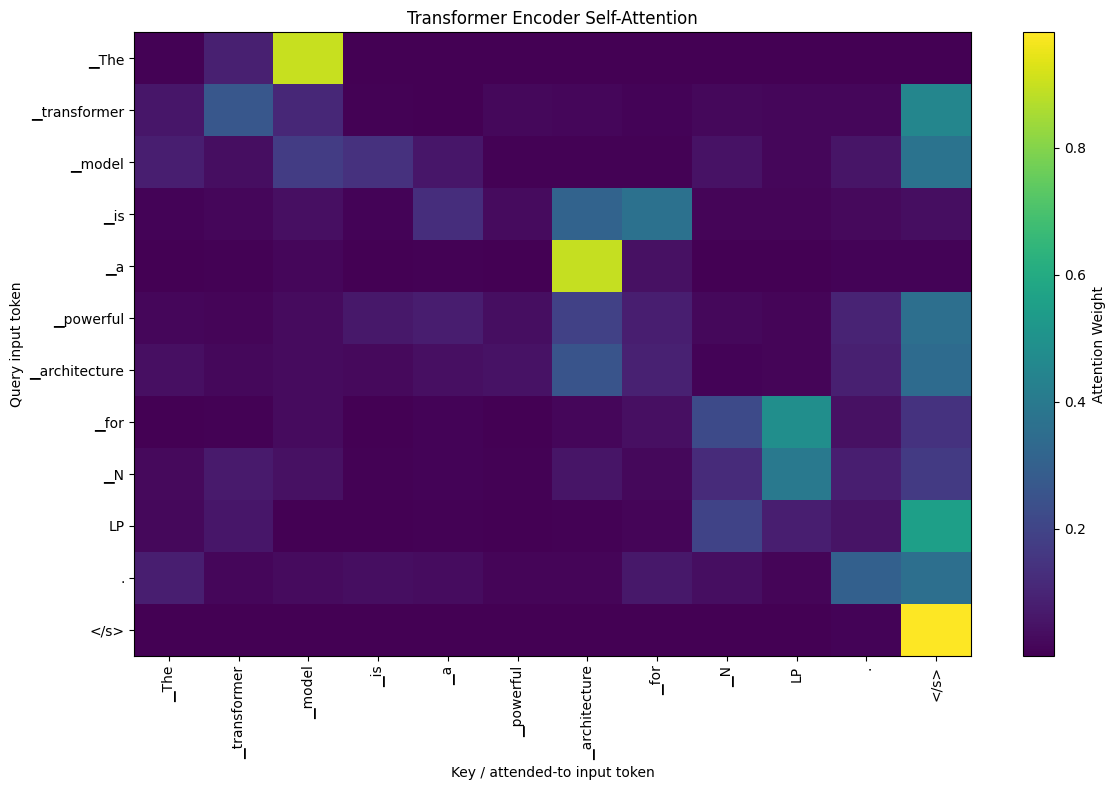

In [ ]:
# Sentence used for attention visualization
attention_sentence = "The transformer model is a powerful architecture for NLP."

inputs = attention_tokenizer(
    attention_sentence,
    return_tensors="pt",
    truncation=True,
    max_length=128
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

# Generate a German translation
generated_ids = attention_model.generate(
    **inputs,
    max_length=128,
    num_beams=4
)

generated_translation = attention_tokenizer.decode(
    generated_ids[0],
    skip_special_tokens=True
)

print("English:")
print(attention_sentence)

print("\nGerman:")
print(generated_translation)


# Use the generated sequence as decoder input
decoder_input_ids = generated_ids[:, :-1]

with torch.no_grad():

    outputs = attention_model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        decoder_input_ids=decoder_input_ids,
        output_attentions=True,
        return_dict=True
    )


# Last encoder layer, first attention head
self_attention = outputs.encoder_attentions[-1][0, 0]

self_attention = self_attention.cpu().numpy()

encoder_tokens = attention_tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0]
)

plt.figure(figsize=(12, 8))

plt.imshow(
    self_attention,
    aspect="auto"
)

plt.xticks(
    range(len(encoder_tokens)),
    encoder_tokens,
    rotation=90
)

plt.yticks(
    range(len(encoder_tokens)),
    encoder_tokens
)

plt.xlabel("Key / attended-to input token")
plt.ylabel("Query input token")
plt.title("Transformer Encoder Self-Attention")

plt.colorbar(label="Attention Weight")

plt.tight_layout()

plt.show()

### 3. Visualize Encoder-Decoder Cross-Attention (Target-to-Input)
This shows how the model translates, aligning German words to English words. This is the part analogous to your LSTM's attention.

English:
The transformer model is a powerful architecture for NLP.

German:
Das Transformatorenmodell ist eine leistungsstarke Architektur für NLP.


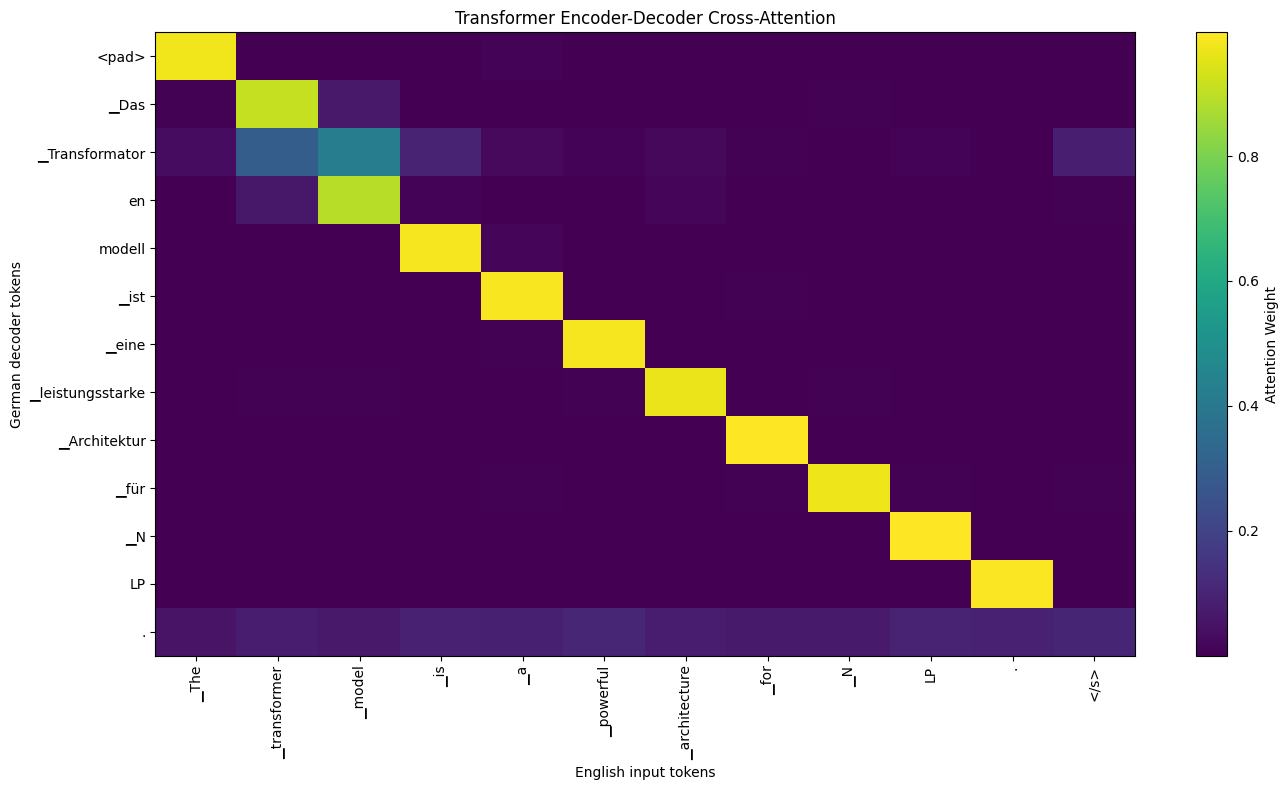

In [ ]:
# Generate the translation again
generated_ids = attention_model.generate(
    **inputs,
    max_length=128,
    num_beams=4
)

generated_translation = attention_tokenizer.decode(
    generated_ids[0],
    skip_special_tokens=True
)

print("English:")
print(attention_sentence)

print("\nGerman:")
print(generated_translation)


# Remove the final EOS token for decoder inputs
decoder_input_ids = generated_ids[:, :-1]

with torch.no_grad():

    outputs = attention_model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        decoder_input_ids=decoder_input_ids,
        output_attentions=True,
        return_dict=True
    )


# Last decoder layer, first attention head
cross_attention = outputs.cross_attentions[-1][0, 0]

cross_attention = cross_attention.cpu().numpy()

source_tokens = attention_tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0]
)

target_tokens = attention_tokenizer.convert_ids_to_tokens(
    decoder_input_ids[0]
)

plt.figure(figsize=(14, 8))

plt.imshow(
    cross_attention,
    aspect="auto"
)

plt.xticks(
    range(len(source_tokens)),
    source_tokens,
    rotation=90
)

plt.yticks(
    range(len(target_tokens)),
    target_tokens
)

plt.xlabel("English input tokens")
plt.ylabel("German decoder tokens")
plt.title("Transformer Encoder-Decoder Cross-Attention")

plt.colorbar(label="Attention Weight")

plt.tight_layout()

plt.show()